# 01 Catalog cleaning

Loads the Kaggle Coursera file (3,522 rows), fixes the broken parts and takes a first look at what's left. Every later notebook reads `data/processed/courses.csv`, so this step has to be right. No API key needed.

In [1]:
# Step 0: setup (works in Colab and on a laptop)
import os, sys
from pathlib import Path

# Colab: where the project folder sits in Google Drive
DRIVE_PROJECT = "/content/drive/MyDrive/LearnPath"

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path(DRIVE_PROJECT)
else:
    PROJECT_DIR = Path.cwd().parent   # running from the notebooks/ folder

assert (PROJECT_DIR / "src" / "learnpath").exists(), f"Project folder not found: {PROJECT_DIR}"
os.environ["LEARNPATH_DIR"] = str(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR / "src"))
print("Project folder:", PROJECT_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/LearnPath


In [2]:
# Step 1: load the raw file
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt
from learnpath import catalog, config, plots

config.ensure_dirs()
plots.apply_style()
raw = catalog.load_raw()
print(raw.shape)
raw.head(3)

(3522, 7)


,name,provider,level_raw,rating_raw,url,description,skills_raw
0,Write A Feature Length Screenplay For Film Or ...,Michigan State University,Beginner,4.8,https://www.coursera.org/learn/write-a-feature...,Write a Full Length Feature Film Script In th...,Drama Comedy peering screenwriting film D...
1,Business Strategy: Business Model Canvas Analy...,Coursera Project Network,Beginner,4.8,https://www.coursera.org/learn/canvas-analysis...,"By the end of this guided project, you will be...",Finance business plan persona (user experien...
2,Silicon Thin Film Solar Cells,�cole Polytechnique,Advanced,4.1,https://www.coursera.org/learn/silicon-thin-fi...,This course consists of a general presentation...,chemistry physics Solar Energy film lambda...


In [3]:
# Step 2: count the problems before changing anything
rating_num = pd.to_numeric(raw["rating_raw"], errors="coerce")
print("Missing values:", raw.isna().sum().sum())
print("Duplicate course URLs:", raw["url"].duplicated().sum())
print("Ratings that are not numbers:", rating_num.isna().sum(), raw.loc[rating_num.isna(), "rating_raw"].unique().tolist())
print("Difficulty levels:", raw["level_raw"].value_counts().to_dict())
print("Descriptions with broken characters:", raw["description"].str.contains("\ufffd").sum())
print()
print("Example Skills value:")
print(repr(raw["skills_raw"].iloc[5]))

Missing values: 0
Duplicate course URLs: 98
Ratings that are not numbers: 82 ['Not Calibrated']
Difficulty levels: {'Beginner': 1444, 'Advanced': 1005, 'Intermediate': 837, 'Conversant': 186, 'Not Calibrated': 50}
Descriptions with broken characters: 1841

Example Skills value:
'maintenance  test case  test automation  screenshot  project  helper class  selenium  reusability  debugging  php computer-science software-development'


The `Skills` column ends with two Coursera category slugs, for example `computer-science software-development`. Those are Coursera's own domain and subdomain, so I split them out and use the subdomain as the course topic.

The skill tags themselves are auto-generated and noisy (a screenwriting course is tagged "unix shells"), so nothing later depends on a single tag.

Cleaning rules:

- Duplicate URLs: keep the first row.
- Broken characters like `You?ll`: put the apostrophe back, a lone `?` between spaces becomes a dash, drop the rest.
- 14 university names lost their accents: fixed by hand.
- Empty or unreadable description: drop the row.
- Level "Conversant" becomes Intermediate. "Not Calibrated" becomes unknown and the course stays.
- Missing rating: median of the same level, flagged.
- Missing topic: most common topic among the 5 most similar courses.

In [4]:
# Step 3: clean
courses, report = catalog.clean_catalog(raw)
pd.DataFrame(report, columns=["step", "rows affected", "note"])

,step,rows affected,note
0,Drop duplicate course URLs,98,kept the first row
1,Restore accented provider names,96,14 universities
2,Repair broken characters in names/descriptions,1806,"apostrophes restored, dashes kept, unrecoverab..."
3,Drop unusable descriptions,2,fewer than 3 words or mostly '?' characters
4,Flag short descriptions (<15 words),4,kept; skills carry most of the signal for these
5,Map 'Conversant' to Intermediate,154,Coursera uses it for language courses
6,Level 'Not Calibrated' set to unknown,49,"kept in catalog, skipped by level filters"
7,Impute 'Not Calibrated' ratings,80,"median rating of the same level, flagged in ra..."
8,Infer missing category from nearest courses,5,5-NN on TF-IDF of name + skills


In [5]:
print(courses.shape)
courses[["course_id", "name", "level", "rating", "domain", "subdomain", "format", "skills_str"]].head()

(3422, 15)


,course_id,name,level,rating,domain,subdomain,format,skills_str
0,C0001,Write A Feature Length Screenplay For Film Or ...,Beginner,4.8,arts-and-humanities,music-and-art,course,drama; comedy; peering; screenwriting; film; d...
1,C0002,Business Strategy: Business Model Canvas Analy...,Beginner,4.8,business,business-strategy,guided_project,finance; business plan; persona (user experien...
2,C0003,Silicon Thin Film Solar Cells,Advanced,4.1,physical-science-and-engineering,electrical-engineering,course,chemistry; physics; solar energy; film; lambda...
3,C0004,Finance for Managers,Intermediate,4.8,business,finance,course,accounts receivable; dupont analysis; analysis...
4,C0005,Retrieve Data using Single-Table SQL Queries,Beginner,4.6,information-technology,data-management,guided_project,data analysis; select (sql); database manageme...


In [6]:
# Each course also gets one text "document" (name, level, topic, skills, short description).
# This is what TF-IDF and the embedding models read.
print(courses["doc"].iloc[1])

Business Strategy: Business Model Canvas Analysis with Miro. Level: Beginner. Topic: business strategy. Skills: finance; business plan; persona (user experience); business model canvas; planning; business; project; product development; presentation; strategy. By the end of this guided project, you will be fluent in identifying and creating Business Model Canvas solutions based on previous high-level analyses and research data. This will enable you to identify and map the elements required for new products and services. Furthermore, it is essential for generating positive results for your business venture. This guided project is designed to engage and harness your visionary and exploratory abilities. You will use proven models in strategy and product development with the Miro platform to explore and analyse your business propositions. We will practice critically examining results from previous analysis and research results in deriving the values for each of the business model sections.


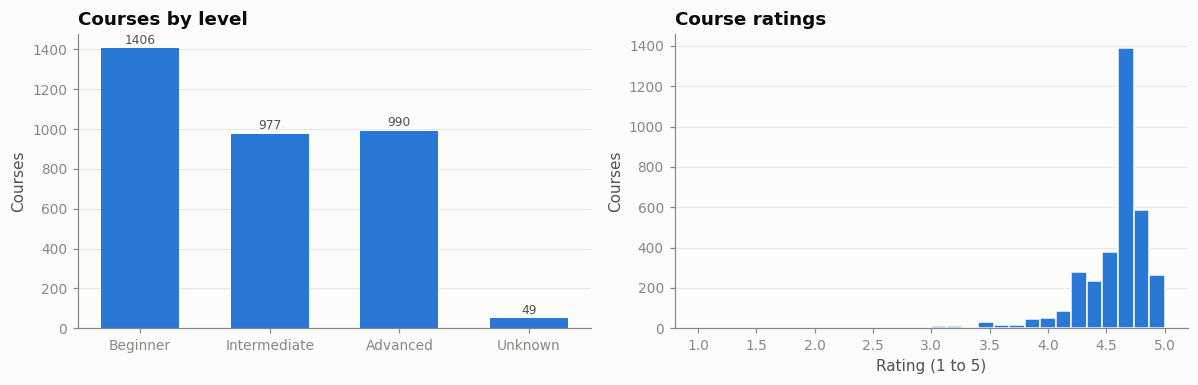

Median rating: 4.6 | share rated 4.5 or higher: 0.76


In [7]:
# Step 4: levels and ratings
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
order = ["Beginner", "Intermediate", "Advanced"]
lv = courses["level"].fillna("Unknown").value_counts().reindex(order + ["Unknown"])
bars = axes[0].bar(lv.index, lv.values, color=plots.PALETTE[0], width=0.6)
plots.label_bars(axes[0], bars)
axes[0].set_title("Courses by level")
axes[0].set_ylabel("Courses")

axes[1].hist(courses["rating"], bins=30, color=plots.PALETTE[0], edgecolor=plots.SURFACE, linewidth=1)
axes[1].set_title("Course ratings")
axes[1].set_xlabel("Rating (1 to 5)")
axes[1].set_ylabel("Courses")
fig.tight_layout()
plots.save(fig, "01_levels_ratings")
plt.show()
print("Median rating:", courses["rating"].median(), "| share rated 4.5 or higher:", round((courses["rating"] >= 4.5).mean(), 2))

Almost every course is rated 4.5 or higher, so rating doesn't separate courses much. Later I give the LLM the completion rate from the logs as a second quality signal.

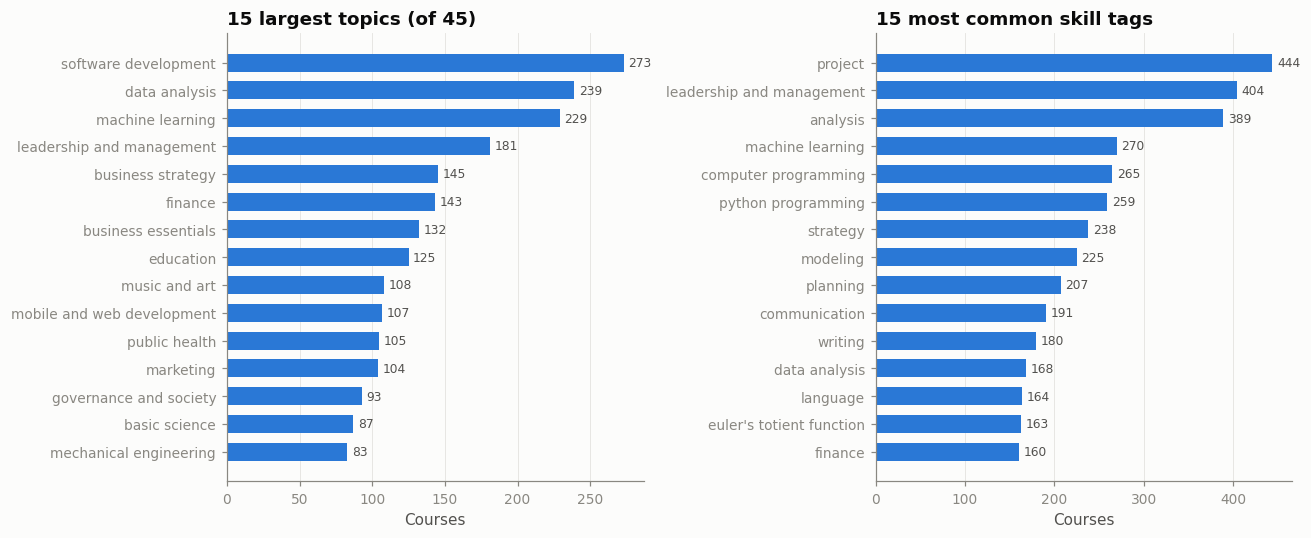

Unique skills: 6137
Courses tagged "euler's totient function": 163


In [8]:
# Step 5: topics and skills
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
top_topics = courses["subdomain"].str.replace("-", " ").value_counts().head(15)[::-1]
bars = axes[0].barh(top_topics.index, top_topics.values, color=plots.PALETTE[0], height=0.65)
plots.label_bars(axes[0], bars, horizontal=True)
axes[0].set_title("15 largest topics (of 45)")
axes[0].set_xlabel("Courses")

skill_counts = Counter(s for sk in courses["skills_str"].str.split("; ") for s in sk)
top_sk = pd.Series(dict(skill_counts.most_common(15)))[::-1]
bars = axes[1].barh(top_sk.index, top_sk.values, color=plots.PALETTE[0], height=0.65)
plots.label_bars(axes[1], bars, horizontal=True)
axes[1].set_title("15 most common skill tags")
axes[1].set_xlabel("Courses")
for ax in axes:
    plots.horizontal_grid(ax)
fig.tight_layout()
plots.save(fig, "01_topics_skills")
plt.show()
print("Unique skills:", len(skill_counts))
print("Courses tagged \"euler's totient function\":", skill_counts["euler's totient function"])

Some of the top skills ("project", "analysis") are too generic to say anything, so notebook 04 drops skills that appear on more than 5% of courses. Also, "euler's totient function" is tagged on 163 courses that have little to do with number theory. More tagging noise.

In [9]:
words = courses["description"].str.split().str.len()
print("Description length in words:", words.describe().round(0).to_dict())
print("Guided projects vs full courses:", courses["format"].value_counts().to_dict())

Description length in words: {'count': 3422.0, 'mean': 179.0, 'std': 107.0, 'min': 3.0, '25%': 109.0, '50%': 160.0, '75%': 224.0, 'max': 1286.0}
Guided projects vs full courses: {'course': 2860, 'guided_project': 562}


In [10]:
# Step 6: save
courses.to_csv(config.COURSES, index=False)
print("Saved", len(courses), "courses to", config.COURSES)

Saved 3422 courses to /content/drive/MyDrive/LearnPath/data/processed/courses.csv
